# Receptive field per anchor → `rf_per_anchor_*.pdf`

On a 2-object trial, take one object as the **anchor** and ask where the unit's receptive
field sits for the *other* object. Conditioning on the anchor being near each of
`N_ANCHORS` positions gives one tuning curve per anchor — so the question is whether the
receptive field **moves with the anchor**.

Two figures per unit, plus one key for all of them:

* **lines** — one panel per anchor: the raw trials, a cosine fit, a dot at the anchor's own
  angle and a star at the fitted receptive-field centre.
* **curve** — those centres as arrows from anchor to centre on a ring, beside the same thing
  in Cartesian form: anchor angle against the conditional preferred direction, at
  `N_CURVE_POINTS` anchors rather than `N_ANCHORS`. The Cartesian panel is where the
  *shape* of the dependence is legible — a retinotopic unit's preferred direction does not
  move with the anchor and lies on a horizontal line, while a relational unit's runs the
  opposite way around the ring and gives a line of slope −1. A slope is hard to read off a
  fan of arrows.
* **legend** — the key means the same thing everywhere, so it is drawn once rather than
  repeated under each figure.

Colour codes the anchor's angle, and means the same thing in every panel of every figure.

In [1]:
import matplotlib.pyplot as plt

import common
import config
import rf_lib

common.set_style()

# (subject, session, unit)
UNITS = [
    ('Perle', '2022-06-11', 188),
    ('Perle', '2022-06-11', 126),
]

FIGSIZE_LINES = (8.8, 1.8)
FIGSIZE_CURVE = (4.8, 2.3)
FIGSIZE_LEGEND = (5.2, 0.45)
OUTPUT_LINES = 'rf_per_anchor_lines_{subject}_{session}_{unit_id}.pdf'
OUTPUT_CURVE = 'rf_per_anchor_curve_{subject}_{session}_{unit_id}.pdf'
OUTPUT_LEGEND = 'rf_per_anchor_legend.pdf'

N_ANCHORS = 6           # anchors, and so line panels
DELTA_THETA_DEG = 5.0   # rotation of the whole set of anchors
WINDOW_DEG = 30.0       # an object counts as at an anchor within this angle of it
MIN_TRIALS = config.MIN_TRIALS_PER_ANCHOR   # anchors below this get no fit
SMOOTH_HALF_WIN_MS = 50 # temporal smoothing half-window of the firing rates

# Points in the curve panel, i.e. anchors it is computed at. Independent of N_ANCHORS: the
# ring carries one arrow per anchor and is unreadable past a handful, while the curve is a
# line and can take as many points as the data support. Past 360/(2*WINDOW_DEG) = 6 the anchor
# windows overlap, so neighbouring points share trials and are not independent.
N_CURVE_POINTS = 6

# SIZE of the fixation cross at the centre of the ring panel, in points (matplotlib's
# `markersize`). Its stroke width scales with it, so this one number keeps the cross's
# proportions rather than making a big cross out of a hairline.
RING_CROSS_SIZE = 8

# Dot area in the curve panel's scatter, in points SQUARED (matplotlib's `s`), so it scales
# as the square of the diameter: doubling it makes a dot ~1.4x wider, not 2x. Goes with
# N_CURVE_POINTS — fewer points want larger dots.
CURVE_POINT_SIZE = 50

# Marker for that scatter, filled with the anchor's colour. Any matplotlib code ('o' circle,
# 's' square, 'D' diamond, '^' triangle, ...).
CURVE_MARKER = 's'

# Ticks on the curve panel. One setting covers both axes — they are the same quantity.
CURVE_TICKS = (0, 180, 360)

# SIZE of the right-hand panel (the scatter + lines), as a fraction of the ring's CIRCLE
# DIAMETER — not of the ring's axes, which runs wider than the circle. The panel is square
# (equal aspect, both axes are the same quantity), so this one number sets both dimensions:
# 1.0 makes it exactly as tall as the ring's circle is wide, below 1 smaller, above 1 larger.
CURVE_HEIGHT_RATIO = 0.8

# Horizontal space between the panels, in INCHES, from the ring circle's right edge to the
# curve's left spine. The curve's y tick labels and axis label sit inside this gap, so a much
# smaller gap makes them collide with the ring.
CURVE_GAP_IN = 0.8

# VERTICAL position of the right-hand panel, in INCHES, positive = UP. 0 centres it on the
# ring, which is what the two panels want when they are the same size — but the ring's arrows
# can crowd one side of it, so a smaller curve panel can read as off-centre even when it is
# exactly centred. Nudge to taste.
CURVE_Y_IN = 0.17

Perle 2022-06-11  unit 188 @ s0/good  |  921 2-obj trials  |  anchors rotated by 5°
  curve: 6/6 anchors fit (>= 5 trials each, +/-30 deg windows)
saved rf_per_anchor_lines_Perle_2022-06-11_188.pdf
saved rf_per_anchor_curve_Perle_2022-06-11_188.pdf


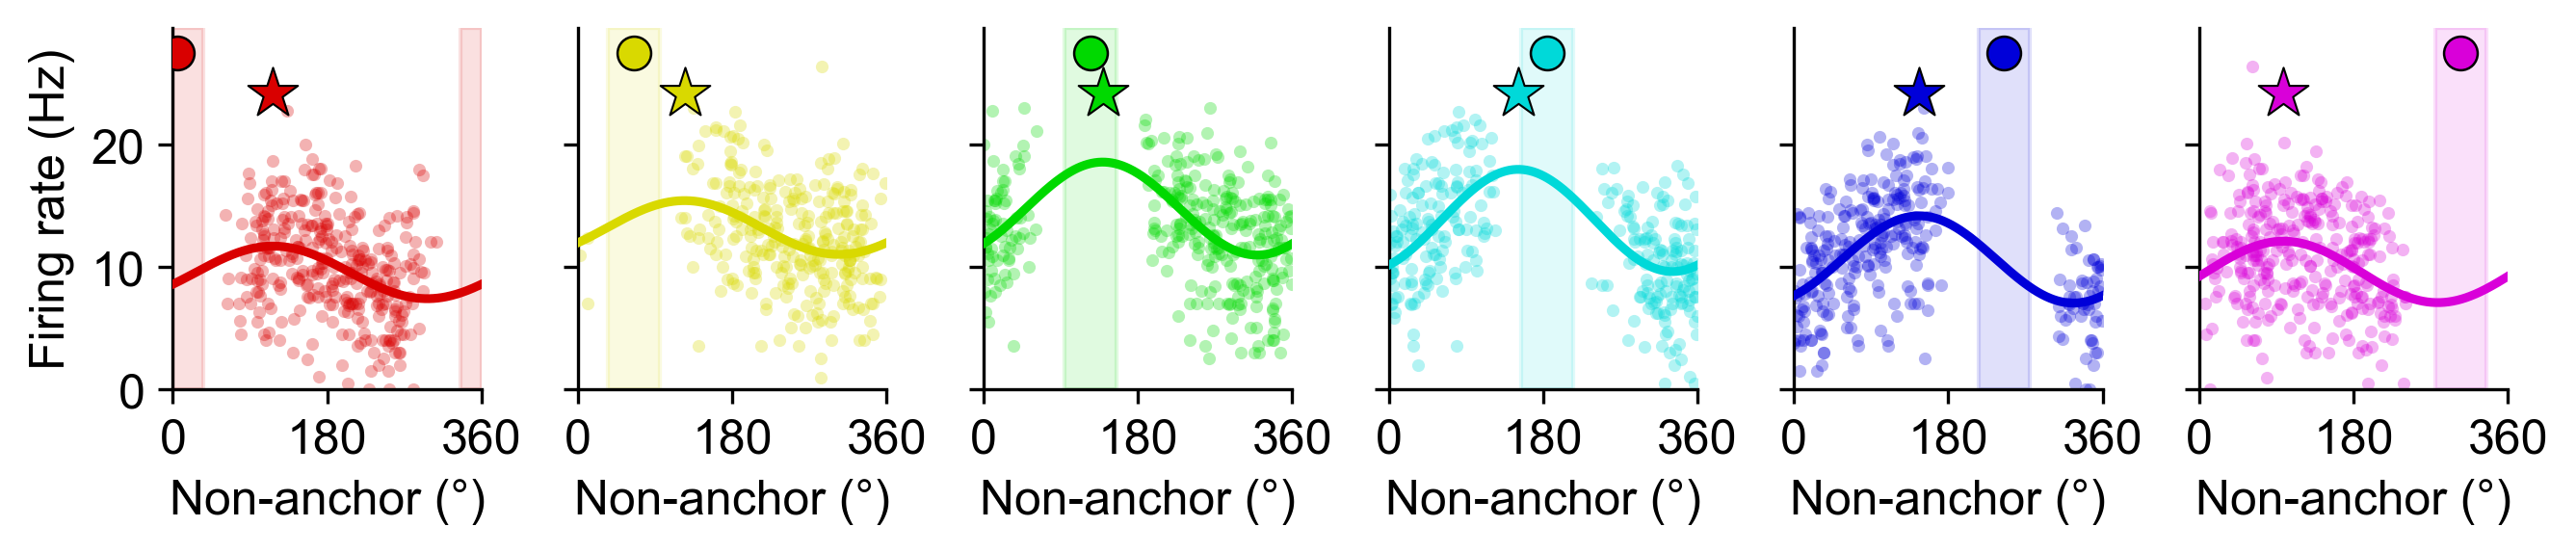

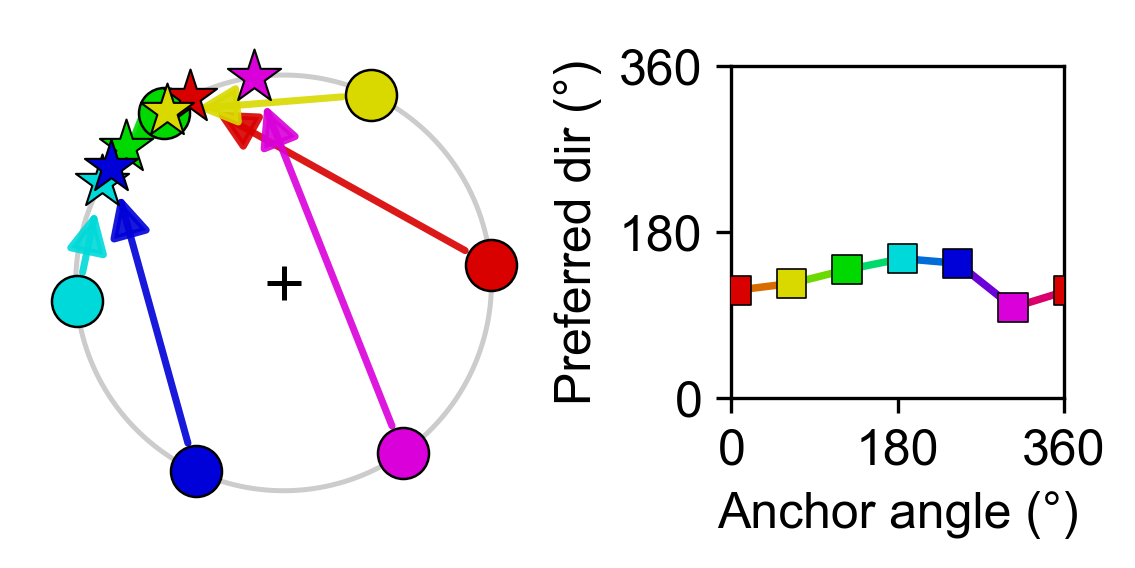

Perle 2022-06-11  unit 126 @ s0/good  |  921 2-obj trials  |  anchors rotated by 5°
  curve: 6/6 anchors fit (>= 5 trials each, +/-30 deg windows)
saved rf_per_anchor_lines_Perle_2022-06-11_126.pdf
saved rf_per_anchor_curve_Perle_2022-06-11_126.pdf


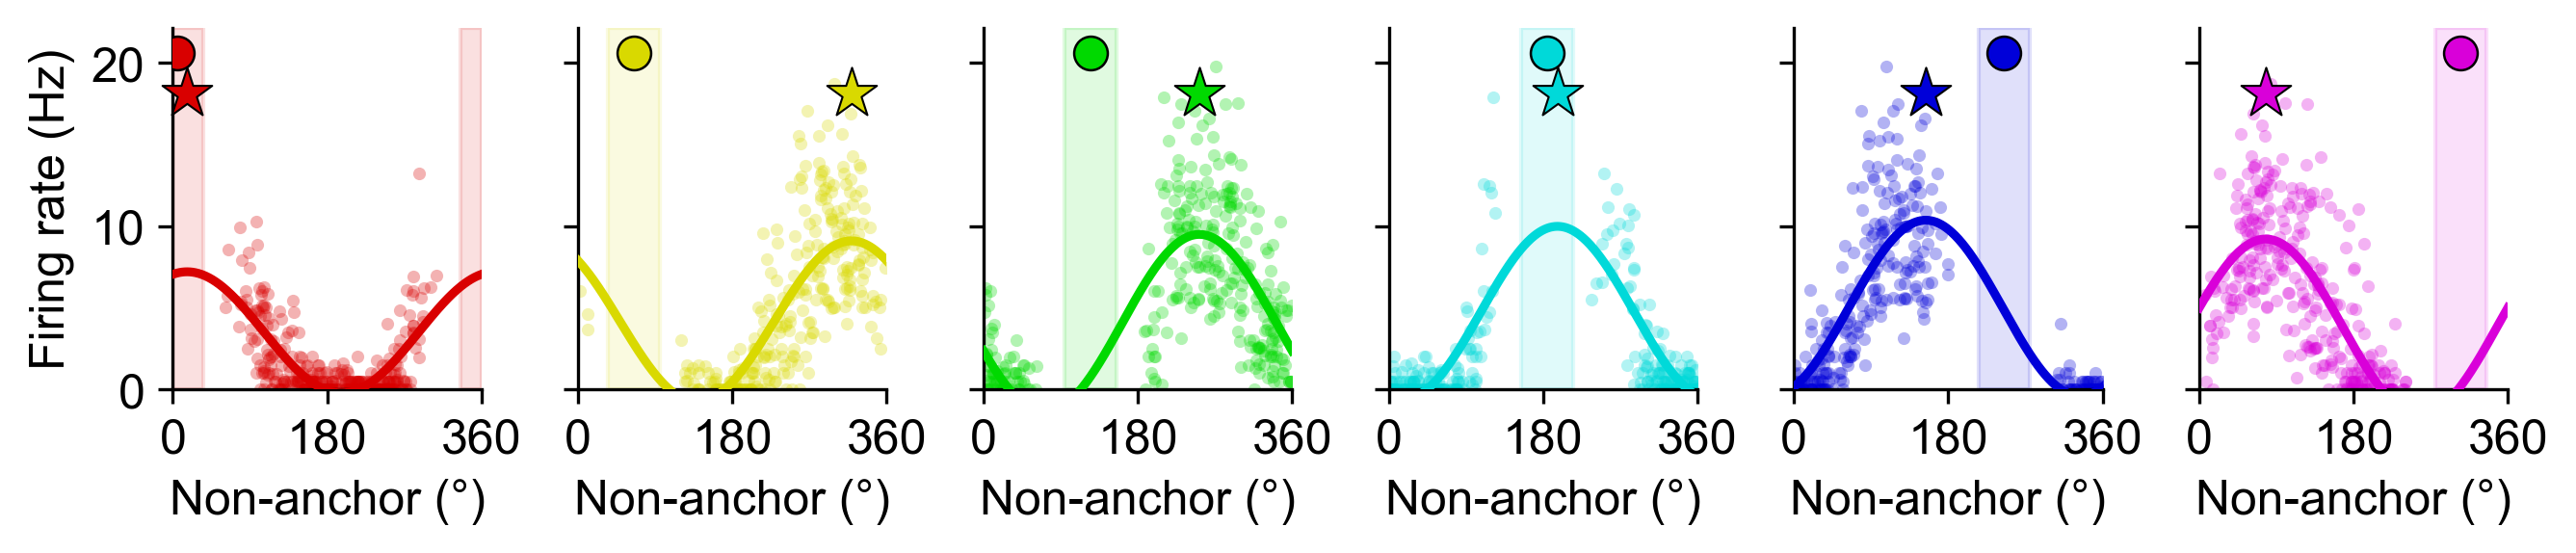

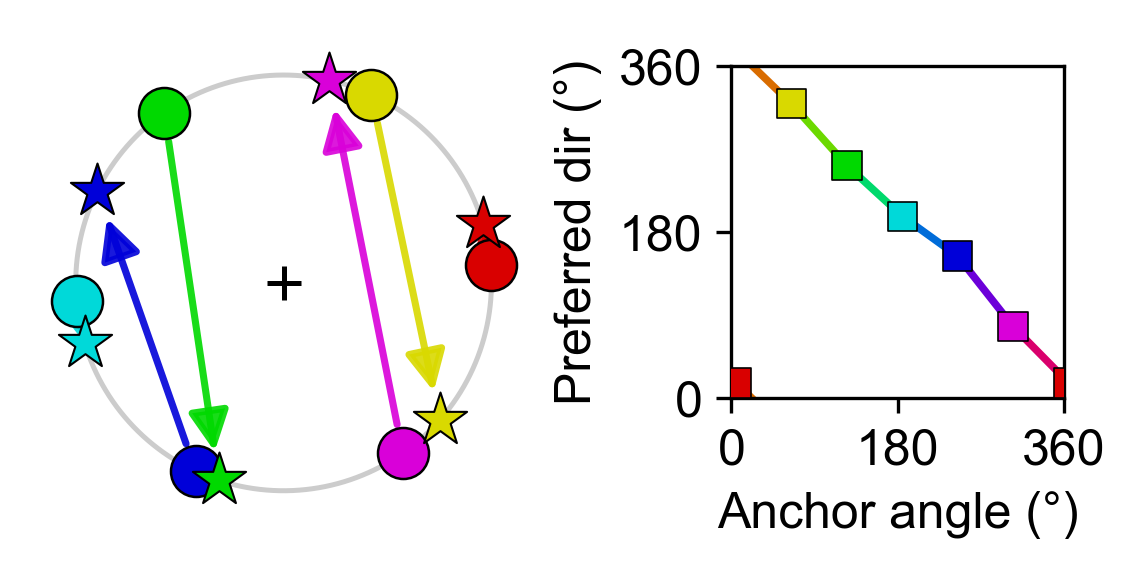

In [2]:
for subject, session, unit_id in UNITS:
    fig_lines, fig_curve = rf_lib.rf_per_anchor_figures(
        subject, session, unit_id, n_anchors=N_ANCHORS, delta_theta_deg=DELTA_THETA_DEG,
        window_deg=WINDOW_DEG, min_trials=MIN_TRIALS,
        smooth_half_win_ms=SMOOTH_HALF_WIN_MS,
        figsize_lines=FIGSIZE_LINES,
        n_curve_points=N_CURVE_POINTS, figsize_curve=FIGSIZE_CURVE,
        curve_point_size=CURVE_POINT_SIZE, curve_height_ratio=CURVE_HEIGHT_RATIO,
        curve_marker=CURVE_MARKER,
        curve_ticks=CURVE_TICKS, curve_gap_in=CURVE_GAP_IN,
        curve_y_in=CURVE_Y_IN, ring_cross_size=RING_CROSS_SIZE)
    names = dict(subject=subject, session=session, unit_id=unit_id)
    common.save(fig_lines, OUTPUT_LINES.format(**names))
    common.save(fig_curve, OUTPUT_CURVE.format(**names))
    plt.show()

## The key

Drawn once, for every unit's figures.

In [3]:
fig = rf_lib.legend_figure(figsize=FIGSIZE_LEGEND)
common.save(fig, OUTPUT_LEGEND)
plt.show()

saved rf_per_anchor_legend.pdf


<Figure size 1560x135 with 0 Axes>